## 05 Area Time Task Organization (Flag 5)

### Dataset Overview
Twenty delivery tasks and a timestamped courier trajectory expose cluster transitions, deadlines, completion order, remaining workload, and delivery pace.

The notebook exposes a primary table and a supporting table (`trajectory_points.csv`).

Goal: Analyze how the courier organizes delivery tasks across space and time, and identify the main operational patterns or trade-offs that shape the route.

Role: Last-mile delivery operations analyst


Category: Courier Route Organization

### Your Objective
Use the provided tables and visual evidence to answer the questions below and summarize the observed trajectory patterns.


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, SVG, display

## Load Dataset

The primary table is loaded into `df`; when available, the supporting trajectory or driver table is loaded into `user_df`.

In [ ]:
dataset_path = "orders.csv"
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv(dataset_path)

In [ ]:
user_dataset_path = "trajectory_points.csv"
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: How does the courier sequence nearby tasks across service clusters, and how often does the route return to a previously served area?

#### Analysis action

Compare consecutive completion labels and cluster transitions.

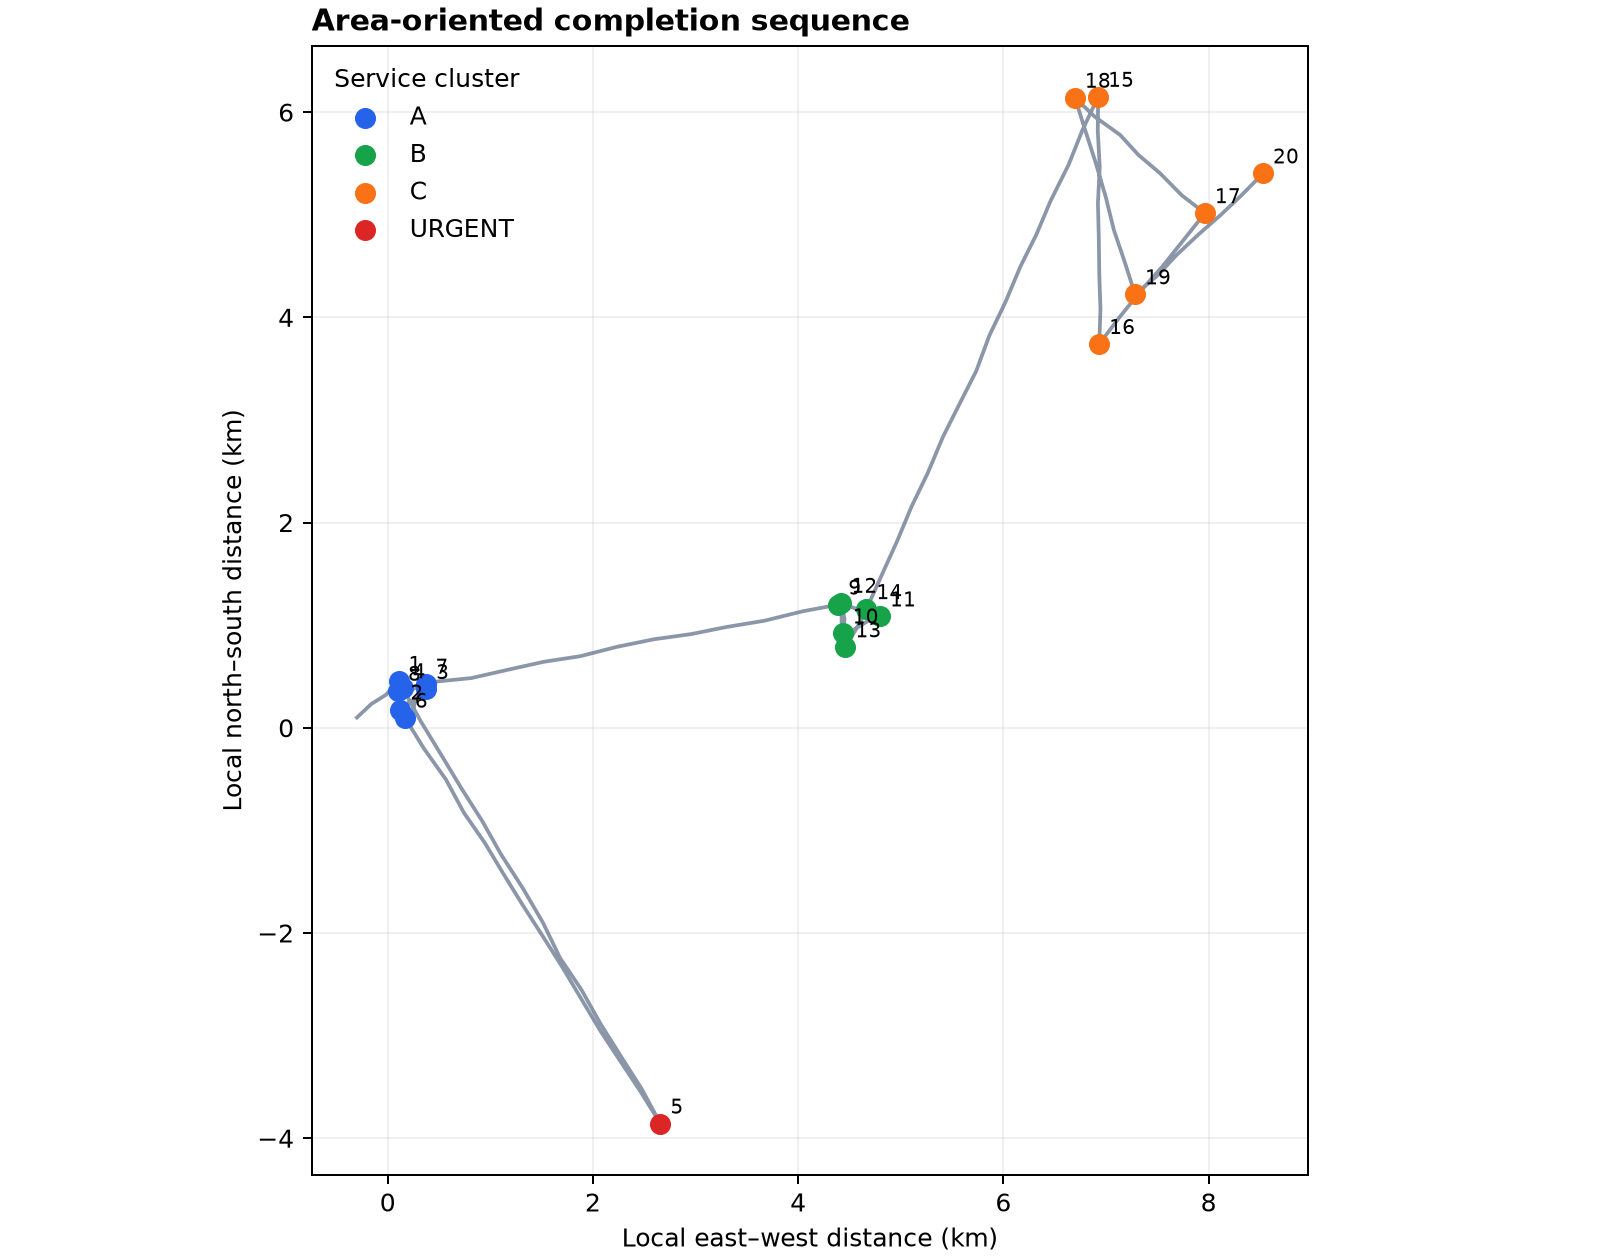

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
d=df.sort_values('completion_sequence'); print(d[['completion_sequence','service_cluster']]); plt.scatter(d.task_x_km,d.task_y_km,c=pd.Categorical(d.service_cluster).codes); plt.show()
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/area_completion_sequence.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "sequence_map",
  "insight": "The courier follows a strongly area-oriented strategy, completing most nearby tasks consecutively before moving to another service cluster, with very few returns to previously visited areas.",
  "insight_value": {
    "area_sequence": [
      "A",
      "URGENT",
      "A",
      "B",
      "C"
    ],
    "returns_to_previous_area": 1
  },
  "plot": {
    "plot_type": "sequence_map",
    "title": "Area-Oriented Completion Sequence",
    "file": "visualizations/area_completion_sequence.png",
    "description": "Tasks are labeled by completion order and colored by service cluster."
  },
  "question": "How does the courier sequence nearby tasks across service clusters, and how often does the route return to a previously served area?",
  "actionable_insight": "Compare consecutive completion labels and cluster transitions.",
  "code": "import pandas as pd\nimport matplotlib.pyplot as plt\nd=df.sort_values('completion_sequence'); print(d[['completion_sequence','service_cluster']]); plt.scatter(d.task_x_km,d.task_y_km,c=pd.Categorical(d.service_cluster).codes); plt.show()",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "task_position",
    "completion_time",
    "task_id",
    "gps_position"
  ]
}

### **Question 2**: Which task interrupts the compact area sequence, and what deadline and spatial evidence explains the detour and return?

#### Analysis action

Relate completion order to task location and deadline slack.

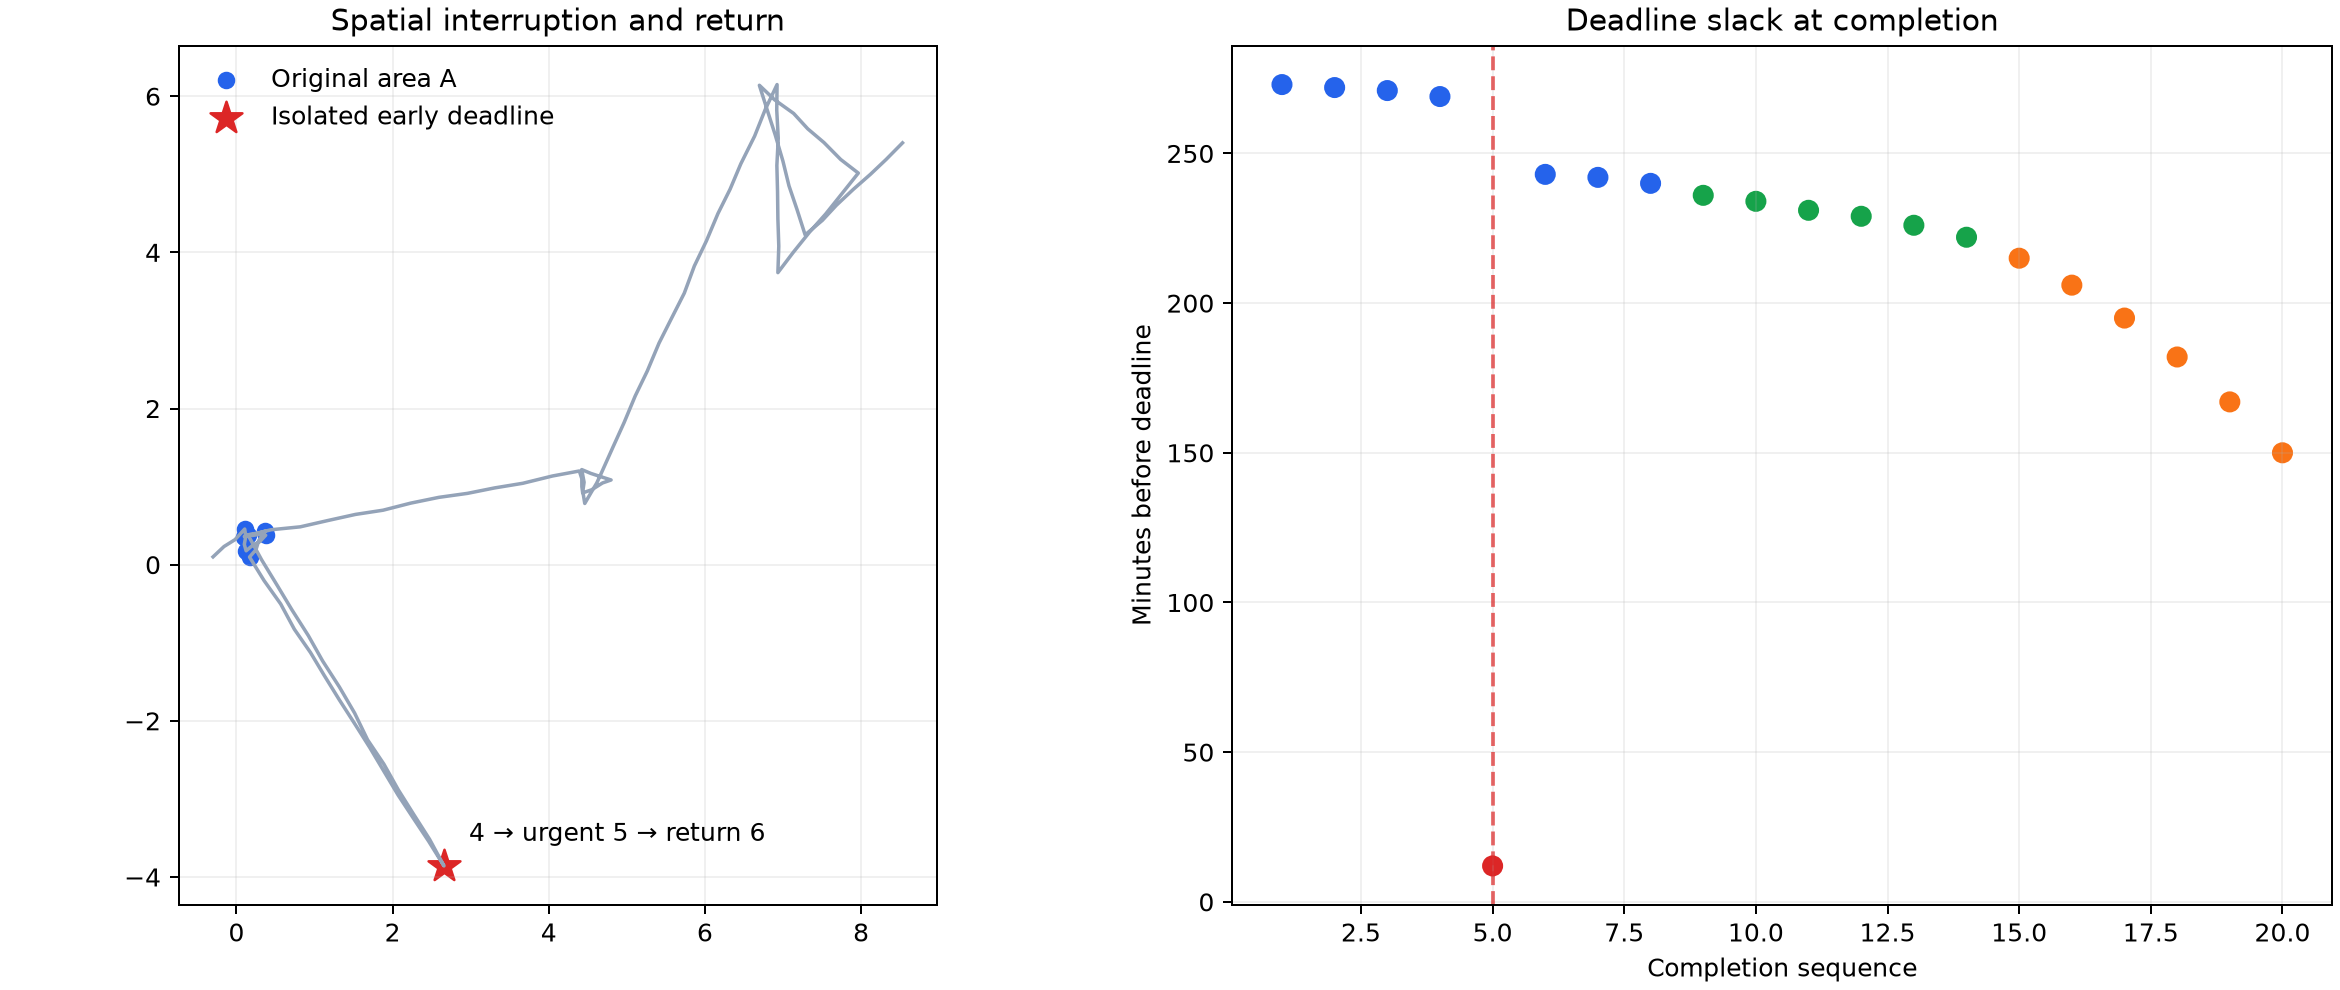

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
d=df.copy(); d['deadline']=pd.to_datetime(d.deadline); d['completion_time']=pd.to_datetime(d.completion_time); d['slack_min']=(d.deadline-d.completion_time).dt.total_seconds()/60; print(d.nsmallest(3,'slack_min')[['task_id','service_cluster','completion_sequence','slack_min']]); plt.scatter(d.completion_sequence,d.slack_min); plt.show()
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/urgent_deadline_interruption.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: High (5 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "deadline_spatial_interruption",
  "insight": "An otherwise compact task sequence is interrupted by a geographically isolated task with a much earlier deadline; after completing it, the courier returns to the original service area.",
  "insight_value": {
    "isolated_task": "LAT5_05",
    "sequence": "A → urgent task → A",
    "urgent_deadline": "09:42"
  },
  "plot": {
    "plot_type": "deadline_spatial_interruption",
    "title": "Early-Deadline Spatial Interruption",
    "file": "visualizations/urgent_deadline_interruption.png",
    "description": "The map and deadline-slack panel isolate the urgent detour and return to area A."
  },
  "question": "Which task interrupts the compact area sequence, and what deadline and spatial evidence explains the detour and return?",
  "actionable_insight": "Relate completion order to task location and deadline slack.",
  "code": "import pandas as pd\nimport matplotlib.pyplot as plt\nd=df.copy(); d['deadline']=pd.to_datetime(d.deadline); d['completion_time']=pd.to_datetime(d.completion_time); d['slack_min']=(d.deadline-d.completion_time).dt.total_seconds()/60; print(d.nsmallest(3,'slack_min')[['task_id','service_cluster','completion_sequence','slack_min']]); plt.scatter(d.completion_sequence,d.slack_min); plt.show()",
  "difficulty_level": 5,
  "difficulty_label": "high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "task_position",
    "completion_time",
    "deadline",
    "task_id",
    "gps_position"
  ]
}

### **Question 3**: How does delivery pace change as the route approaches its final, spatially dispersed tasks?

#### Analysis action

Compare inter-completion intervals with pending-task count and completion phase.

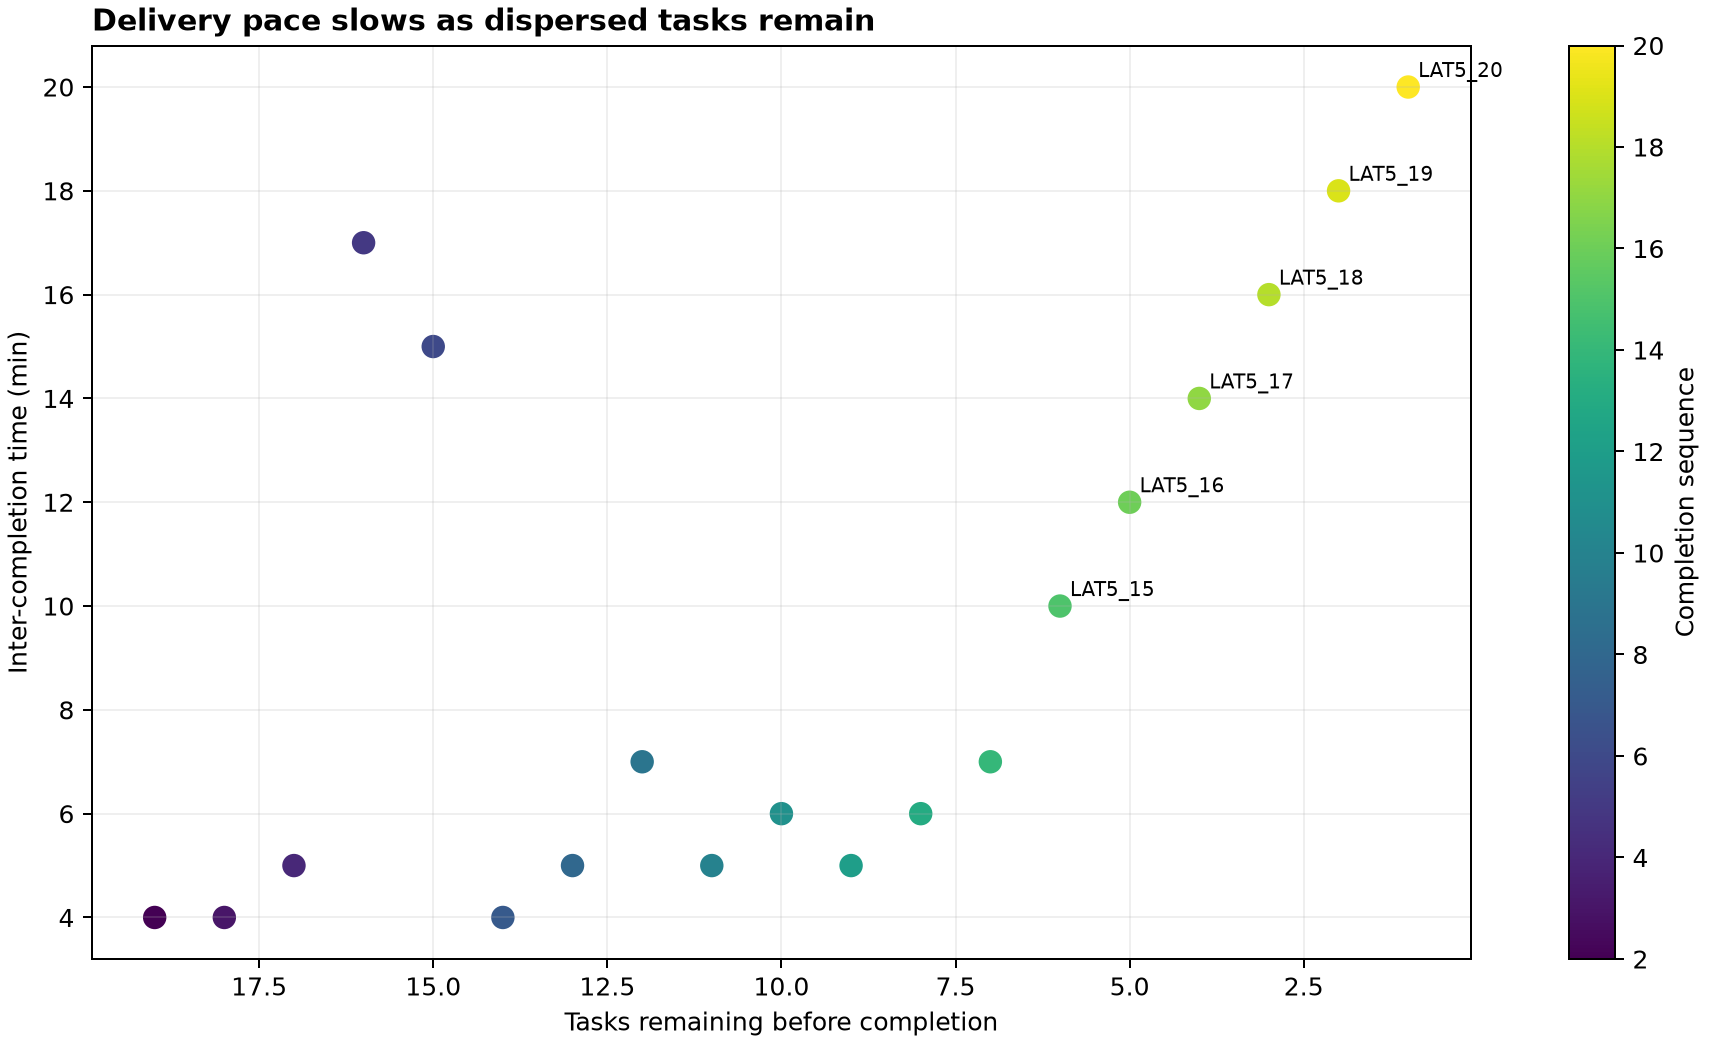

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
d=df[df.completion_sequence>1]; plt.scatter(d.pending_tasks_before_completion,d.inter_completion_minutes,c=d.completion_sequence); plt.gca().invert_xaxis(); plt.show(); print(d.groupby(d.completion_sequence>14).inter_completion_minutes.median())
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/pace_vs_remaining_tasks.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: High (5 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "pace_dispersion_tradeoff",
  "insight": "Task completion is rapid while orders remain densely clustered, but the delivery pace slows markedly near the end of the route as the remaining tasks become fewer and more spatially dispersed.",
  "insight_value": {
    "early_dense_median_interval_min": 5.0,
    "final_six_median_interval_min": 15.0
  },
  "plot": {
    "plot_type": "pace_dispersion_tradeoff",
    "title": "Pace versus Remaining Tasks",
    "file": "visualizations/pace_vs_remaining_tasks.png",
    "description": "Time between consecutive task completions is shown against the declining number of pending tasks."
  },
  "question": "How does delivery pace change as the route approaches its final, spatially dispersed tasks?",
  "actionable_insight": "Compare inter-completion intervals with pending-task count and completion phase.",
  "code": "import pandas as pd\nimport matplotlib.pyplot as plt\nd=df[df.completion_sequence>1]; plt.scatter(d.pending_tasks_before_completion,d.inter_completion_minutes,c=d.completion_sequence); plt.gca().invert_xaxis(); plt.show(); print(d.groupby(d.completion_sequence>14).inter_completion_minutes.median())",
  "difficulty_level": 5,
  "difficulty_label": "high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "task_position",
    "completion_time",
    "gps_time",
    "gps_position",
    "task_id"
  ]
}

### Summary of Findings (Flag 5)

The route is mostly organized cluster by cluster, with one early-deadline task causing the only clear return to a previous area. Completion remains fast through dense clusters and slows as the final tasks become sparse and geographically dispersed.